# DSCI 552 - Homework 5

**Name:** Chen Zhu  
**GitHub username:** ChenZhu50  
**USC ID:** 2370790492


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

data_path = '../data'

## 1(a) Load data


In [2]:
cols = ['temp', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning_urethra', 'bladder', 'nephritis']
# UTF-16, tab separated, decimal comma (35,9)
df = pd.read_csv(data_path + '/diagnosis.data', encoding='utf-16', sep='\t', decimal=',', header=None, names=cols)
df[cols[1:]] = (df[cols[1:]] == 'yes').astype(int)
print(df.shape)
df.head()

(120, 8)


,temp,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


## 1(b) Decision tree

> **Label powerset or binary relevance?** Label powerset. There are only 2 labels, so only 4 classes, and one tree keeps the relation between the two diseases. Binary relevance would treat them as independent.


bladder      40
nephritis    31
none         30
both         19
Name: count, dtype: int64
train accuracy: 1.0 leaves: 6 depth: 4


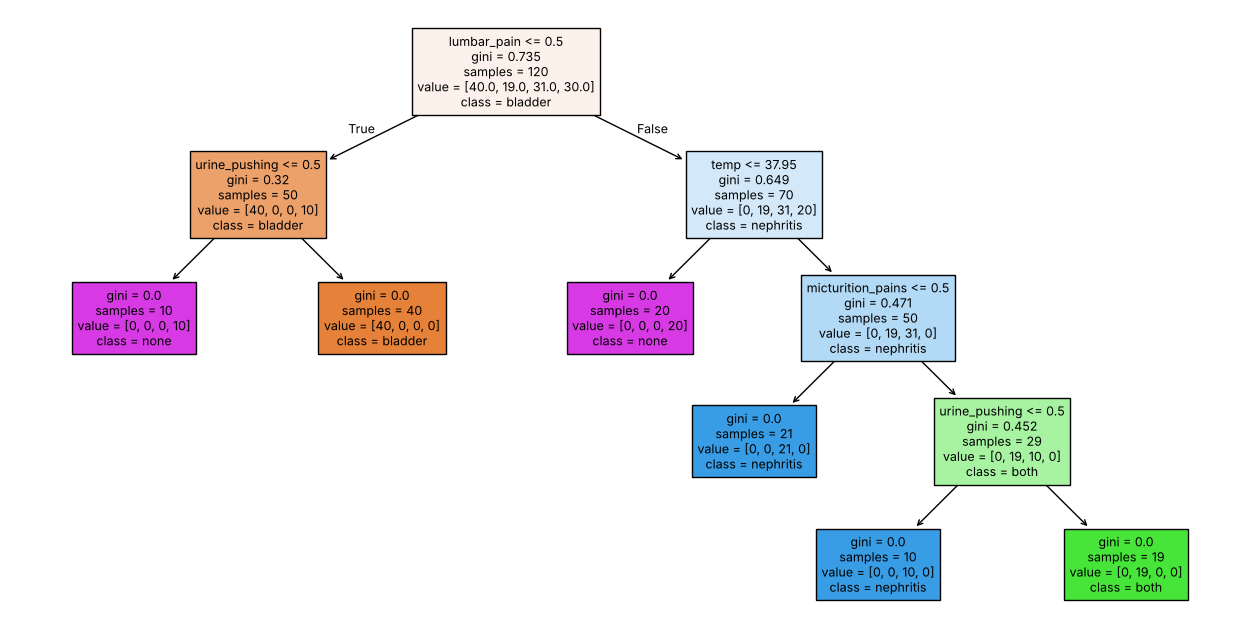

In [3]:
X = df[cols[:6]]
# label powerset: 2 labels -> 4 classes
names = {(0, 0): 'none', (1, 0): 'bladder', (0, 1): 'nephritis', (1, 1): 'both'}
y = np.array([names[(b, n)] for b, n in zip(df.bladder, df.nephritis)])
print(pd.Series(y).value_counts())

tree = DecisionTreeClassifier(random_state=552).fit(X, y)
print('train accuracy:', tree.score(X, y), 'leaves:', tree.get_n_leaves(), 'depth:', tree.get_depth())

plt.figure(figsize=(16, 8))
plot_tree(tree, feature_names=cols[:6], class_names=tree.classes_, filled=True, fontsize=9)
plt.show()

## 1(c) IF-THEN rules


In [4]:
def get_rules(model):
    t = model.tree_
    rules = []

    def walk(node, conds):
        if t.children_left[node] == -1:  # leaf
            label = model.classes_[t.value[node].argmax()]
            rules.append('IF ' + ' AND '.join(conds) + ' THEN ' + label)
            return
        name, thr = cols[t.feature[node]], t.threshold[node]
        if name == 'temp':  # every other feature is 0/1, so print it as no / yes
            left, right = f'temp <= {thr:.2f}', f'temp > {thr:.2f}'
        else:
            left, right = name + ' = no', name + ' = yes'
        walk(t.children_left[node], conds + [left])
        walk(t.children_right[node], conds + [right])

    walk(0, [])
    return rules

for r in get_rules(tree):
    print(r)

IF lumbar_pain = no AND urine_pushing = no THEN none
IF lumbar_pain = no AND urine_pushing = yes THEN bladder
IF lumbar_pain = yes AND temp <= 37.95 THEN none
IF lumbar_pain = yes AND temp > 37.95 AND micturition_pains = no THEN nephritis
IF lumbar_pain = yes AND temp > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis
IF lumbar_pain = yes AND temp > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both


> The tree checks lumbar pain first, then temperature, then micturition pains / urine pushing. For example, no lumbar pain + urine pushing → bladder inflammation only, and lumbar pain + temp > 37.95 + micturition pains + urine pushing → both diseases.


## 1(d) Cost-complexity pruning


In [5]:
alphas = tree.cost_complexity_pruning_path(X, y).ccp_alphas[:-1]  # last alpha prunes everything down to the root
# rows are sorted by temp, so shuffle
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)

prune_results = []
for a in alphas:
    model = DecisionTreeClassifier(ccp_alpha=a, random_state=552)
    prune_results.append([a, cross_val_score(model, X, y, cv=cv).mean(), model.fit(X, y).get_n_leaves()])
prune_results = pd.DataFrame(prune_results, columns=['alpha', 'cv_acc', 'leaves'])
prune_results

,alpha,cv_acc,leaves
0,0.000000,0.991667,6
1,0.098167,0.858333,4
2,0.133333,0.766667,3
3,0.182000,0.675000,2


alpha: 0.0 leaves: 6 train accuracy: 1.0


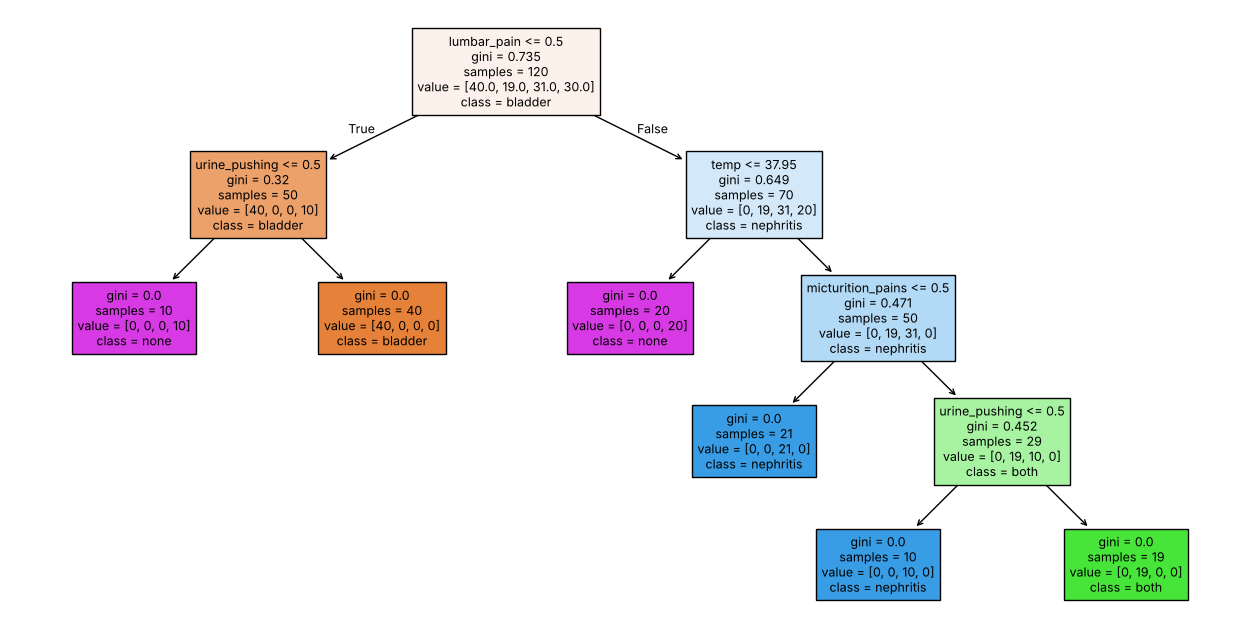

IF lumbar_pain = no AND urine_pushing = no THEN none
IF lumbar_pain = no AND urine_pushing = yes THEN bladder
IF lumbar_pain = yes AND temp <= 37.95 THEN none
IF lumbar_pain = yes AND temp > 37.95 AND micturition_pains = no THEN nephritis
IF lumbar_pain = yes AND temp > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis
IF lumbar_pain = yes AND temp > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both


In [6]:
# largest alpha with the best CV accuracy = smallest tree that doesn't lose accuracy
best_alpha = prune_results[prune_results.cv_acc == prune_results.cv_acc.max()].alpha.max()
pruned = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=552).fit(X, y)
print('alpha:', best_alpha, 'leaves:', pruned.get_n_leaves(), 'train accuracy:', pruned.score(X, y))

plt.figure(figsize=(16, 8))
plot_tree(pruned, feature_names=cols[:6], class_names=pruned.classes_, filled=True, fontsize=9)
plt.show()

for r in get_rules(pruned):
    print(r)

alpha: 0.09816666666666667 leaves: 4 train accuracy: 0.8416666666666667


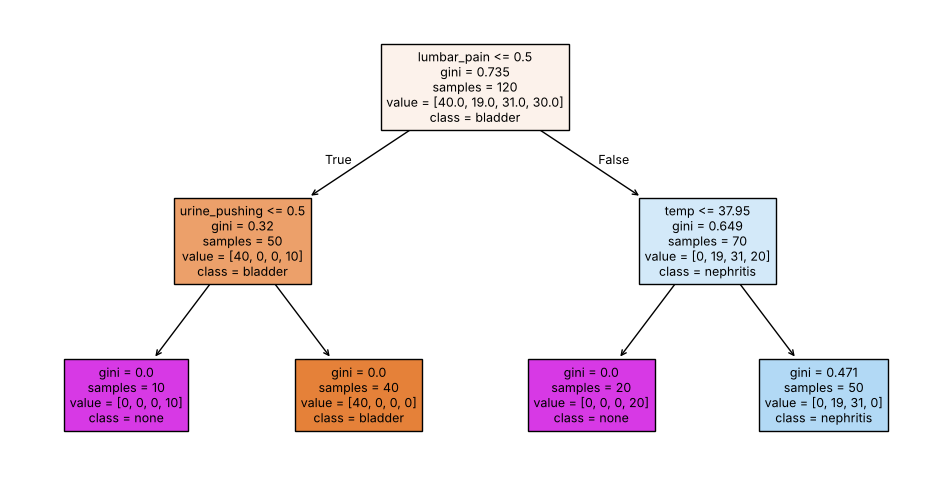

IF lumbar_pain = no AND urine_pushing = no THEN none
IF lumbar_pain = no AND urine_pushing = yes THEN bladder
IF lumbar_pain = yes AND temp <= 37.95 THEN none
IF lumbar_pain = yes AND temp > 37.95 THEN nephritis


In [7]:
# next tree on the pruning path, to compare
small = DecisionTreeClassifier(ccp_alpha=prune_results.alpha[1], random_state=552).fit(X, y)
print('alpha:', prune_results.alpha[1], 'leaves:', small.get_n_leaves(), 'train accuracy:', small.score(X, y))

plt.figure(figsize=(12, 6))
plot_tree(small, feature_names=cols[:6], class_names=small.classes_, filled=True, fontsize=9)
plt.show()

for r in get_rules(small):
    print(r)

> **Answer:** The best CV accuracy (99.17%) is at alpha = 0, so the minimal tree from pruning is the full 6-leaf tree, with the same rules as in 1(c). It is only minimal on this pruning path: a tree that splits on nausea → urine_pushing → lumbar_pain also gets all 120 rows right with 5 leaves, but pruning can't reach it.
>
> The 4-leaf tree above is easier to read, but accuracy drops to 84.17% (train) / 85.83% (CV), mainly because it never predicts 'both'. I'd keep the 6-leaf tree.


## 2(a) Load data (first 1495 rows = train)


In [8]:
col_names = [line.split()[1] for line in open(data_path + '/communities.names') if line.startswith('@attribute')]
crime = pd.read_csv(data_path + '/communities.data', header=None, names=col_names, na_values='?')
print(crime.shape)

(1994, 128)


## 2(b) Drop non-predictive features, median imputation


In [9]:
crime = crime.drop(columns=['state', 'county', 'community', 'communityname', 'fold'])
missing = crime.isna().sum()
print(missing[missing > 0])

target = 'ViolentCrimesPerPop'
train = crime.iloc[:1495]
test = crime.iloc[1495:]
X_train, y_train = train.drop(columns=target), train[target]  # still has NaN, models impute inside the pipeline
X_test, y_test = test.drop(columns=target), test[target]
print(X_train.shape, X_test.shape)

train_filled = train.fillna(train.median())  # only for (c)-(e)

OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64
(1495, 122) (499, 122)


> **Why median:** the missing values are almost all in the 22 LEMAS police columns (84% missing), and the features are very skewed with outliers (see 2(e)), so the median is safer than the mean. It is computed on the training folds only (imputer inside the Pipeline), so no validation or test data leaks into it.


## 2(c) Correlation matrix


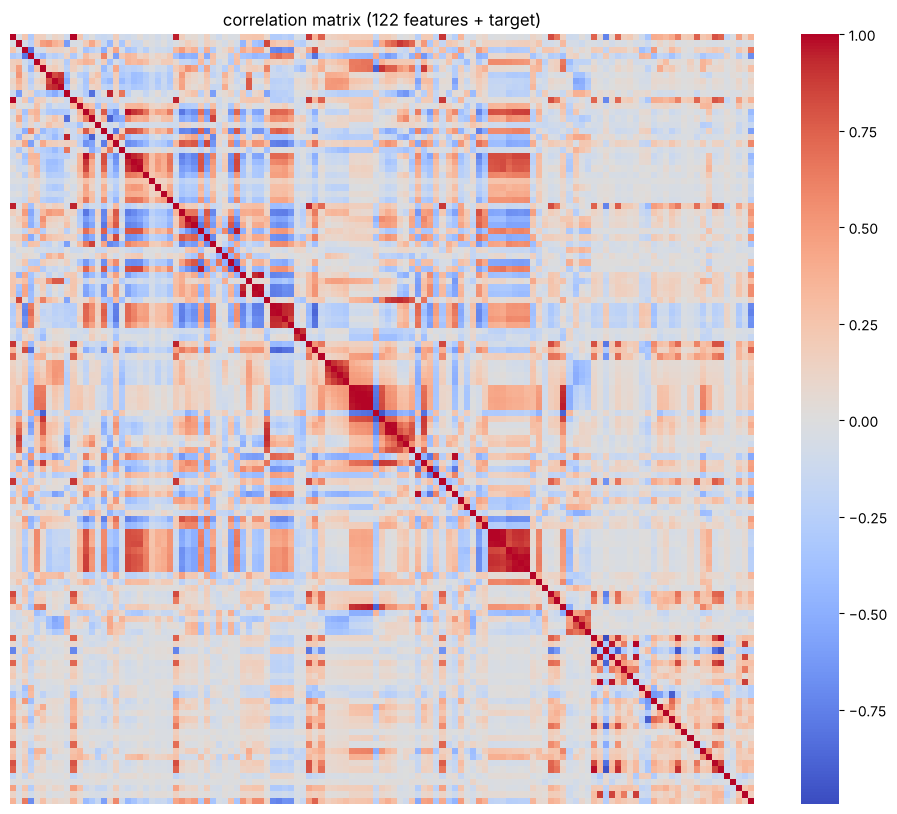

In [10]:
plt.figure(figsize=(12, 10))
sns.heatmap(train_filled.corr(), cmap='coolwarm', center=0, xticklabels=False, yticklabels=False)
plt.title('correlation matrix (122 features + target)')
plt.show()

> There are many dark red / dark blue blocks, so a lot of features are strongly correlated with each other (e.g. the income features, the family-structure features). This suggests OLS may be unstable here and regularization or PCR may help.


## 2(d) Coefficient of Variation


In [11]:
X_filled = train_filled.drop(columns=target)
cv_feat = (X_filled.std() / X_filled.mean()).sort_values(ascending=False)
cv_feat.head(15)

PctPolicAsian          5.527059
NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
LemasSwornFT           2.248042
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
PolicOperBudg          1.645508
LandArea               1.645408
racePctHisp            1.612091
PctNotSpeakEnglWell    1.456618
dtype: float64

> Most of the top features are counts (NumStreet, NumInShelters, NumIlleg, NumImmig, population...). They are close to 0 for most communities and large for a few big cities, so their spread is large relative to their mean. PctPolicAsian is first because 84% of it was filled with one median value, which makes the few real values look like big outliers.


## 2(e) Top ⌊√128⌋ = 11 features by CV


['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


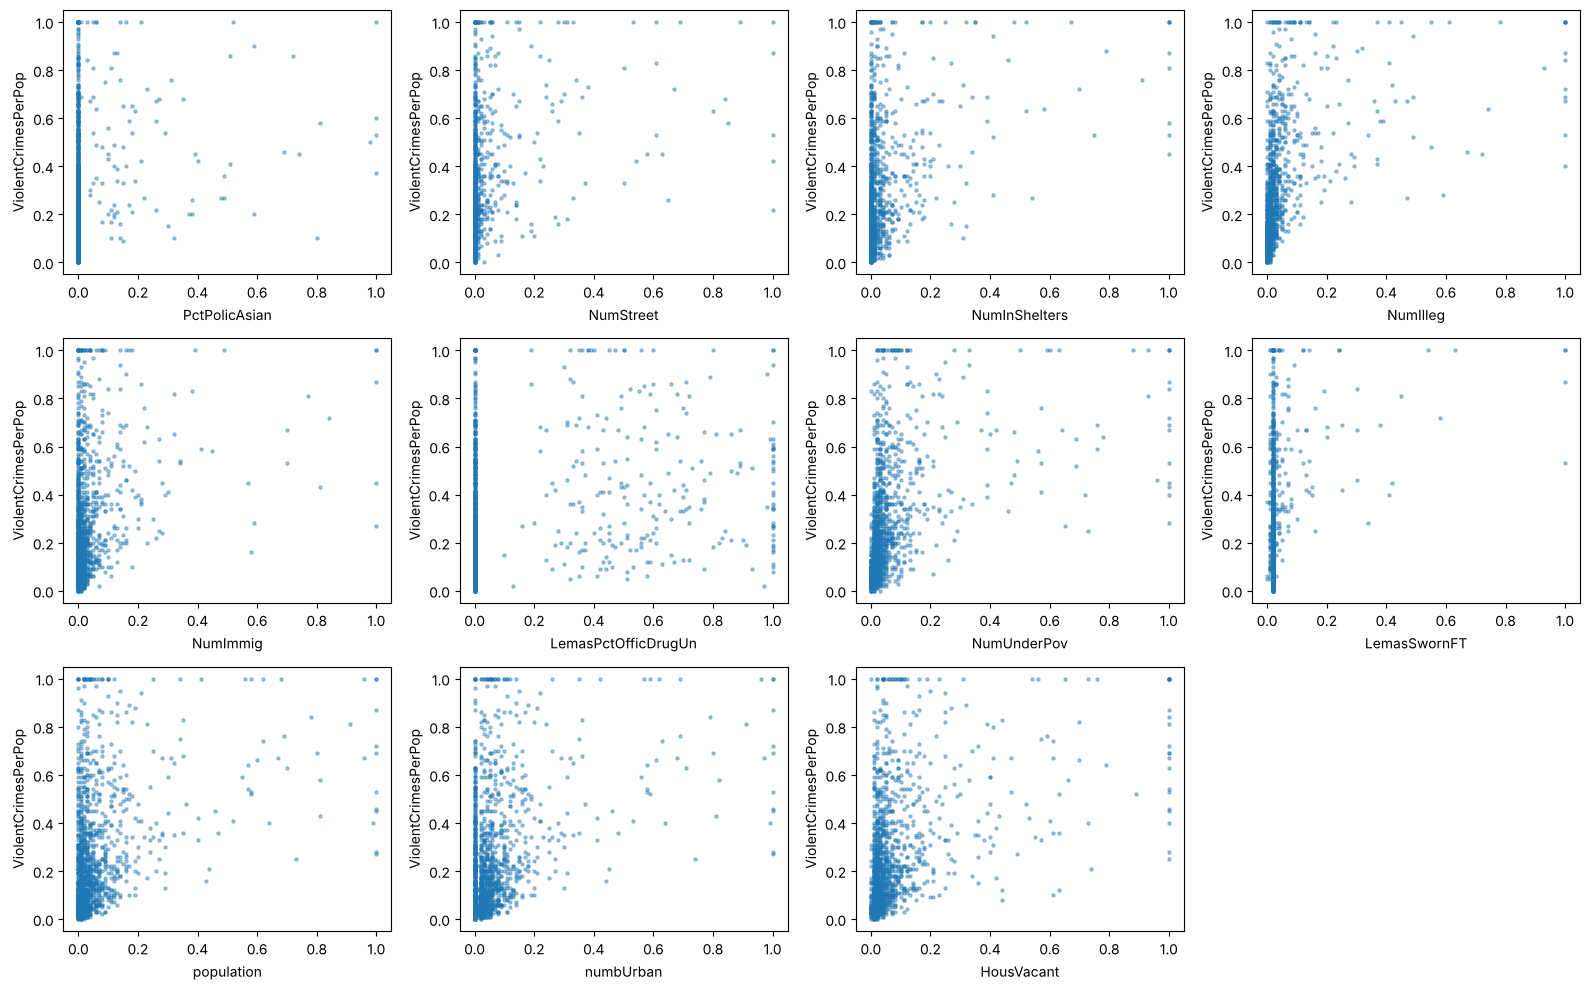

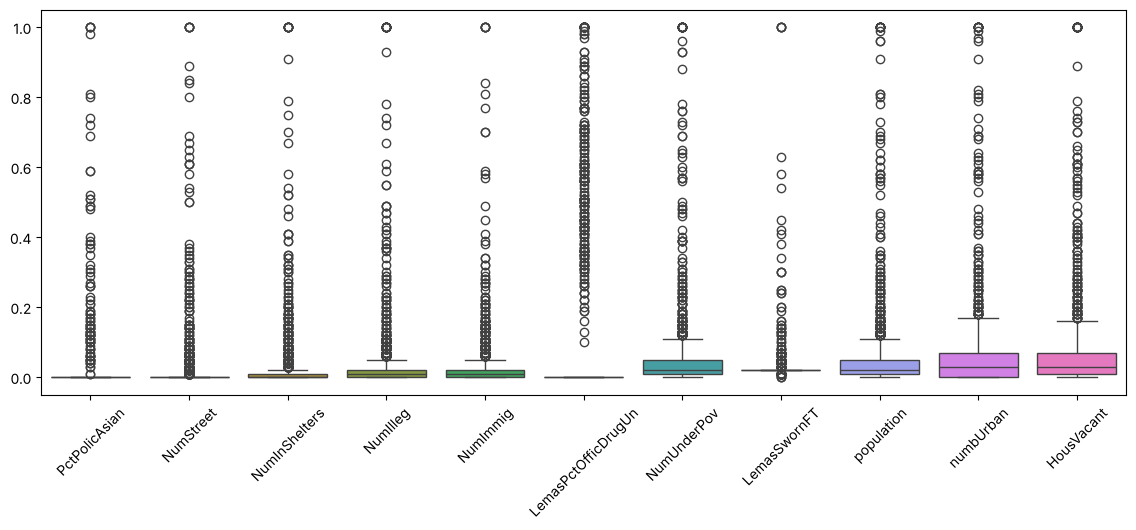

In [12]:
top = cv_feat.index[:int(np.sqrt(128))]
print(list(top))

fig, ax = plt.subplots(3, 4, figsize=(16, 10))
for a, feat in zip(ax.flat, top):
    a.scatter(X_filled[feat], y_train, s=5, alpha=0.4)
    a.set_xlabel(feat)
    a.set_ylabel(target)
ax.flat[-1].axis('off')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
sns.boxplot(data=X_filled[top])
plt.xticks(rotation=45)
plt.show()

> **Answer: No.** Most points are squeezed near x = 0 with a few large values, so there's no clear trend. High CV only means high spread, not a strong relationship with the target (PctPolicAsian is first only because 84% of it was imputed with the median). Each plot shows one feature alone while the features are highly correlated, so significance needs a formal test such as regression p-values.


## 2(f) Linear regression


In [13]:
results = {}
ols = Pipeline([('impute', SimpleImputer(strategy='median')), ('lr', LinearRegression())]).fit(X_train, y_train)
results['OLS'] = mean_squared_error(y_test, ols.predict(X_test))
print('OLS test MSE:', results['OLS'])

OLS test MSE: 0.017966215426067328


## 2(g) Ridge regression


In [14]:
kf = KFold(n_splits=10, shuffle=True, random_state=552)

# imputer (and scaler) are inside the pipeline, so CV fits them on the training folds only
def fit_cv(steps, grid):
    pipe = Pipeline([('impute', SimpleImputer(strategy='median'))] + steps)
    search = GridSearchCV(pipe, grid, cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
    return search, mean_squared_error(y_test, search.predict(X_test))

ridge, results['Ridge'] = fit_cv([('ridge', Ridge())], {'ridge__alpha': np.logspace(-3, 3, 100)})
print('best lambda:', ridge.best_params_['ridge__alpha'], 'Ridge test MSE:', results['Ridge'])

best lambda: 2.1544346900318843 Ridge test MSE: 0.01752504626275198


## 2(h) LASSO


In [15]:
lambdas = np.logspace(-6, -1, 60)

lasso, results['LASSO'] = fit_cv([('lasso', Lasso(max_iter=10000))], {'lasso__alpha': lambdas})
coef = lasso.best_estimator_.named_steps['lasso'].coef_
selected = X_train.columns[coef != 0]
print('best lambda:', lasso.best_params_['lasso__alpha'], 'LASSO test MSE:', results['LASSO'])
print(len(selected), 'selected variables:', list(selected))

best lambda: 8.895134973108236e-05 LASSO test MSE: 0.017679584675399363
76 selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', '

In [16]:
import warnings
# the smallest lambdas in the grid don't converge on standardized features; they are never the best lambda anyway
warnings.filterwarnings('ignore', message='Objective did not converge')

lasso_s, results['LASSO (standardized)'] = fit_cv([('scale', StandardScaler()), ('lasso', Lasso(max_iter=10000))],
                                                  {'lasso__alpha': lambdas})
coef_s = lasso_s.best_estimator_.named_steps['lasso'].coef_
selected_s = X_train.columns[coef_s != 0]
print('best lambda:', lasso_s.best_params_['lasso__alpha'], 'LASSO (standardized) test MSE:', results['LASSO (standardized)'])
print(len(selected_s), 'selected variables:', list(selected_s))
print('selected by both:', len(set(selected) & set(selected_s)))
print('feature std range:', X_filled.std().min(), '-', X_filled.std().max())

best lambda: 0.0006260516572014815 LASSO (standardized) test MSE: 0.017724564168107654
76 selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc

> **Answer:** Test MSE is 0.01768 (original) vs 0.01772 (standardized), almost the same in this run. Both select 76 variables (lists above), 74 of them in common. The selections differ a bit because the feature stds range from 0.05 to 0.45, so standardizing changes how much each coefficient is penalized.


## 2(i) PCR


best M: 97 PCR test MSE: 0.018365945241841722


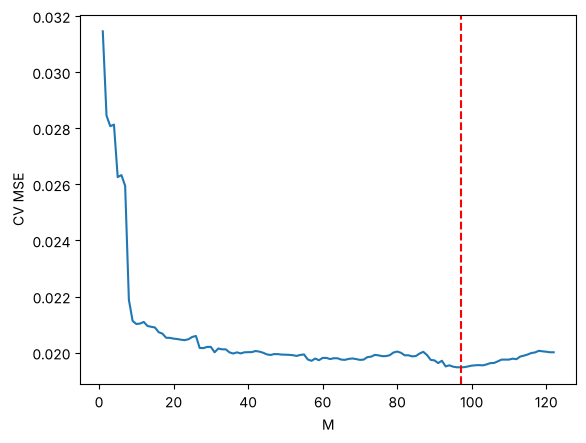

In [17]:
# PCR = standardize + PCA + linear regression
pcr, results['PCR'] = fit_cv([('scale', StandardScaler()), ('pca', PCA()), ('lr', LinearRegression())],
                             {'pca__n_components': range(1, X_train.shape[1] + 1)})
best_M = pcr.best_params_['pca__n_components']
print('best M:', best_M, 'PCR test MSE:', results['PCR'])

plt.plot(range(1, X_train.shape[1] + 1), -pcr.cv_results_['mean_test_score'])
plt.axvline(best_M, ls='--', c='r')
plt.xlabel('M')
plt.ylabel('CV MSE')
plt.show()

## 2(j) L1-penalized gradient boosting tree (XGBoost)


In [18]:
# reg_alpha = L1 penalty on the leaf weights
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=552)
xgb, results['XGBoost (L1)'] = fit_cv([('xgb', xgb)], {'xgb__reg_alpha': [0, 0.001, 0.01, 0.1, 0.5, 1, 5, 10]})
print(pd.DataFrame({'alpha': xgb.cv_results_['param_xgb__reg_alpha'], 'cv_mse': -xgb.cv_results_['mean_test_score']}))
print('best alpha:', xgb.best_params_['xgb__reg_alpha'], 'XGBoost test MSE:', results['XGBoost (L1)'])

    alpha    cv_mse
0   0.000  0.019533
1   0.001  0.019579
2   0.010  0.019450
3   0.100  0.019626
4   0.500  0.019137
5   1.000  0.019170
6   5.000  0.019977
7  10.000  0.020871
best alpha: 0.5 XGBoost test MSE: 0.016682024064232838


## Summary


In [19]:
pd.Series(results, name='test_mse').sort_values().to_frame()

,test_mse
XGBoost (L1),0.016682
Ridge,0.017525
LASSO,0.017680
LASSO (standardized),0.017725
OLS,0.017966
PCR,0.018366
